<a href="https://cognitiveclass.ai"><img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DL0101EN-SkillsNetwork/images/IDSN-logo.png" width="400"> </a>

# Classification Models with Keras

Estimated time needed: **30** mins


## Introduction


In this lab, we will learn how to use the Keras library to build models for classificaiton problems. We will use the popular MNIST dataset, a dataset of images, for a change. 

The <strong>MNIST database</strong>, short for Modified National Institute of Standards and Technology database, is a large database of handwritten digits that is commonly used for training various image processing systems. The database is also widely used for training and testing in the field of machine learning.
    
The MNIST database contains 60,000 training images and 10,000 testing images of digits written by high school students and employees of the United States Census Bureau.

Also, this way, you will get to compare how conventional neural networks compare to convolutional neural networks, that we will build in the next module.


## Objectives for this Notebook    
* Use the MNIST database for training various image processing systems
* Build a neural network
* Train and test the network


## Table of Contents

<div class="alert alert-block alert-info" style="margin-top: 20px">

<font size = 3>

1. <a href="#Import-Keras-and-Packages">Import Keras and Packages</a>      
2. <a href="#Build-a-Neural-Network">Build a Neural Network</a>     
3. <a href="#Train-and-Test-the-Network">Train and Test the Network</a>     

</font>
</div>


Let's start by installing Keras and other necessary libraries.


The following required libraries are __not__ pre-installed in the Skills Network Labs environment. __You will need to run the following cell__ to install them:


In [1]:
!pip install tensorflow_cpu==2.18.0
!pip install matplotlib==3.9.2

print("==== All required libraries are installed =====")
# All Libraries required for this lab are listed below. The libraries pre-installed on Skills Network Labs are commented. 
# If you run this notebook on a different environment, e.g. your desktop, you may need to uncomment and install certain libraries.

#!pip install numpy==1.21.4
#!pip install pandas==1.3.4
#!pip install keras==2.1.6
#!pip install matplotlib==3.5.0

# Installing the libraries, if not installed. Run the following lines to install the required libraries for this lab:
# Terminal>   pip install numpy
# Terminal>   pip install pandas
# Terminal>   pip install keras
# Terminal>   pip install matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/230.3 MB ? eta -:--:--
   ━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/230.3 MB 63.6 MB/s eta 0:00:04
   ━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.2/230.3 MB 67.4 MB/s eta 0:00:04
   ━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.8/230.3 MB 64.3 MB/s eta 0:00:03
   ━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.3/230.3 MB 67.3 MB/s eta 0:00:03
   ━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/230.3 MB 68.2 MB/s eta 0:00:03
   ━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━ 81.5/230.3 MB 67.3 MB/s eta 0:00:03
   ━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━ 93.6/230.3 MB 66.3 MB/s eta 0:00:03
   ━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━ 108.5/230.3 MB 67.3 MB/s eta 0:00:02
   ━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━ 122.4/230.3 MB 67.4 MB/s eta 0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━ 132.6/230.3 MB 65.7 MB/s eta 0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━ 141.6/230.3 MB 63.7 MB/s eta 0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━ 1

#### Suppress the tensorflow warning messages
We use the following code to  suppress the warning messages due to use of CPU architechture for tensoflow.

You may want to **comment out** these lines if you are using the GPU architechture


In [ ]:
import os  # The os module in Python provides a way of using operating system dependent functionality like
#  reading or writing to the file system, managing environment variables, and
#  interacting with the operating system in various ways. It allows you to perform tasks such as creating directories, listing files, and
#  manipulating paths in a platform-independent manner.
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0' # This line sets the environment variable 'TF_ENABLE_ONEDNN_OPTS' to '0',
#  which disables the use of oneDNN optimizations in TensorFlow.
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # This line sets the environment variable 'TF_CPP_MIN_LOG_LEVEL' to '2',
#  which suppresses TensorFlow's logging messages with a severity level of 'INFO' and 'WARNING'. Only messages with a severity level of 'ERROR' will be displayed.
#  This can help reduce the amount of output generated by TensorFlow, making it easier to focus on important messages and errors

## Import Keras and Packages


### Import the libraries. 
There might be some warning messages related to floating point round off errors and lack of GPU and other compiler related options. You can ignore these warnings and proceed.


In [2]:
import keras  # Keras is a high-level neural networks API, written in Python and
#  capable of running on top of TensorFlow, CNTK, or Theano.
#  It allows for easy and fast prototyping of deep learning models.

from keras.models import Sequential  # Sequential is a linear stack of layers in Keras.
#  It allows you to create a model layer by layer. You can add layers to the model using the add() method.
from keras.layers import Dense # Dense is a fully connected layer in Keras.
# It is used to create a layer of neurons in a neural network. 
# Each neuron in a Dense layer receives input from all neurons in the previous layer and sends output to all neurons in the next layer.
from keras.layers import Input # Input is a Keras layer that is used to define the input shape of a model. 
# It is typically used as the first layer in a model to specify the expected input dimensions.
from keras.utils import to_categorical # to_categorical is a function in Keras that converts a class vector (integers) to binary class matrix.
# This is useful for categorical classification problems where the target variable is represented as integers.


Since we are dealing we images, let's also import the Matplotlib scripting layer in order to view the images.


In [3]:
import matplotlib.pyplot as plt  # Matplotlib is a plotting library for the Python programming language
# and its numerical mathematics extension NumPy.
#  It provides an object-oriented API for embedding plots into applications using general-purpose GUI toolkits like Tkinter, wxPython, Qt, or GTK.
#  It is widely used for data visualization in machine learning and deep learning projects.

The Keras library conveniently includes the MNIST dataset as part of its API. You can check other datasets within the Keras library [here](https://keras.io/datasets/). 

So, let's load the MNIST dataset from the Keras library. The dataset is readily divided into a training set and a test set.


In [4]:
# import the data, which is the MNIST dataset of handwritten digits, from Keras datasets module
#  The MNIST dataset is a collection of 70,000 grayscale images of handwritten digits (0-9) that
#  are commonly used for training and testing machine learning models in the field of computer vision.
from keras.datasets import mnist

# read the data, which is split into training and testing sets. The training set contains 60,000 images and
#  the testing set contains 10,000 images. Each image is a 28x28 pixel grayscale image, and
#  the corresponding labels are the digits (0-9) represented in the images.
(X_train, y_train), (X_test, y_test) = mnist.load_data()

Let's confirm the number of images in each set. According to the dataset's documentation, we should have 60000 images in X_train and 10000 images in the X_test.


In [5]:
X_train.shape  # The shape of the training data is (60000, 28, 28), which means there are 60,000 images in the training set,
      # and each image is a 28x28 pixel grayscale image. The first dimension (60000) represents the number of samples,
      #  while the second and third dimensions (28, 28) represent the height and width of each image, respectively.

(60000, 28, 28)

The first number in the output tuple is the number of images, and the other two numbers are the size of the images in datset. So, each image is 28 pixels by 28 pixels.


Let's visualize the first image in the training set using Matplotlib's scripting layer.


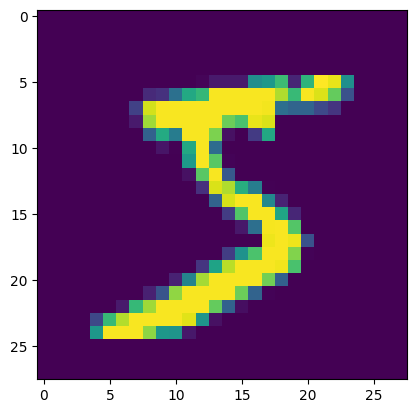

In [6]:
plt.imshow(X_train[0]) # This line of code uses the imshow() function from the Matplotlib library
   # to display the first image in the training dataset (X_train[0]). The imshow() function takes a 2D array
   #    (in this case, the pixel values of the image) and renders it as an image.

With conventional neural networks, we cannot feed in the image as input as is. So we need to flatten the images into one-dimensional vectors, each of size 1 x (28 x 28) = 1 x 784.


In [ ]:
# To flatten images into one-dimensional vector

num_pixels = X_train.shape[1] * X_train.shape[2] # find size of one-dimensional vector
   #  by multiplying the height and width of the images (28 * 28 = 784),
   #  which gives us the total number of pixels in each image. This value is stored in the variable num_pixels.

X_train = X_train.reshape(X_train.shape[0], num_pixels).astype('float32') # flatten training images
 # The reshape() function is used to change the shape of the training data (X_train)
 #  from its original shape of (60000, 28, 28) to a new shape of (60000, 784).
X_test = X_test.reshape(X_test.shape[0], num_pixels).astype('float32') # flatten test images
# The reshape() function is used to change the shape of the test data (X_test)
#  from its original shape of (10000, 28, 28) to a new shape of (10000, 784).

Since pixel values can range from 0 to 255, let's normalize the vectors to be between 0 and 1.


In [8]:
# To normalize inputs from 0-255 to 0-1
X_train = X_train / 255  # This line of code normalizes the pixel values of the training data (X_train)
 # by dividing each pixel value by 255.
X_test = X_test / 255   # This line of code normalizes the pixel values of the test data (X_test)
 # by dividing each pixel value by 255.

Finally, before we start building our model, remember that for classification we need to divide our target variable into categories. We use the to_categorical function from the Keras Utilities package.


In [9]:
# one hot encode outputs
y_train = to_categorical(y_train) # This line of code converts the class vector (y_train)
 # to a binary class matrix using the to_categorical() function from Keras.
y_test = to_categorical(y_test)   # This line of code converts the class vector (y_test)
 # to a binary class matrix using the to_categorical() function from Keras.

num_classes = y_test.shape[1] # This line of code calculates the number of classes in the dataset
   # by accessing the second dimension of the y_test array.
print(num_classes)  # The output of this line will be 10, which indicates that
   # there are 10 classes in the dataset (digits 0-9). 

10


## Build a Neural Network


In [10]:
# define classification model - function to create model
def classification_model():
    # create model
    
    model = Sequential()  # This line of code initializes a Sequential model in Keras,
      # which is a linear stack of layers. You can add layers to the model using the add() method.
    model.add(Input(shape=(num_pixels,))) # This line of code adds an Input layer to the model,
      # specifying the shape of the input data. 
    model.add(Dense(num_pixels, activation='relu')) # This line of code adds a Dense layer to the model
       # with num_pixels neurons and ReLU activation function. 
    model.add(Dense(100, activation='relu'))    # This line of code adds another Dense layer to the model
       # with 100 neurons and ReLU activation function.
    model.add(Dense(num_classes, activation='softmax'))  # This line of code adds a Dense layer to the model
        # with num_classes neurons and softmax activation function.
    
    
    # compile model
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
     # This line of code compiles the model by specifying the optimizer, loss function, and evaluation metric.
     # The optimizer is set to 'adam', which is an efficient optimization algorithm for training neural networks.
     # The loss function is set to 'categorical_crossentropy', which is commonly used for multi-class classification problems.
     # The evaluation metric is set to 'accuracy', which will be used to evaluate the performance of the model during training and testing.
    return model  # This line of code returns the compiled model, which can then be used for training and evaluation.

## Train and Test the Network


In [12]:
# build the model
model = classification_model() # This line of code calls the classification_model() function 
# to build and compile the model, and assigns it to the variable model.

# fit the model
model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, verbose=2)
# The fit() method is used to train the model on the training data (X_train and y_train) for a specified number of epochs (10 in this case).
# The validation_data parameter is set to (X_test, y_test), which means that the model will be evaluated on the test data after each epoch to monitor its performance. The verbose parameter is

# evaluate the model
scores = model.evaluate(X_test, y_test, verbose=0) 
  #  This line of code evaluates the performance of the trained model on the 
  #  test data (X_test and y_test) using the evaluate() method. The verbose parameter is set to 0, 
  #  which means that no output will be displayed during the evaluation process. 
  #  The results of the evaluation (loss and accuracy) will be stored in the variable scores.
scores

Epoch 1/10
1875/1875 - 22s - 12ms/step - accuracy: 0.9441 - loss: 0.1869 - val_accuracy: 0.9703 - val_loss: 0.0934
Epoch 2/10
1875/1875 - 18s - 10ms/step - accuracy: 0.9759 - loss: 0.0776 - val_accuracy: 0.9743 - val_loss: 0.0837
Epoch 3/10
1875/1875 - 20s - 11ms/step - accuracy: 0.9831 - loss: 0.0528 - val_accuracy: 0.9752 - val_loss: 0.0788
Epoch 4/10
1875/1875 - 18s - 9ms/step - accuracy: 0.9874 - loss: 0.0414 - val_accuracy: 0.9740 - val_loss: 0.0910
Epoch 5/10
1875/1875 - 17s - 9ms/step - accuracy: 0.9898 - loss: 0.0326 - val_accuracy: 0.9797 - val_loss: 0.0709
Epoch 6/10
1875/1875 - 17s - 9ms/step - accuracy: 0.9922 - loss: 0.0248 - val_accuracy: 0.9803 - val_loss: 0.0779
Epoch 7/10
1875/1875 - 18s - 9ms/step - accuracy: 0.9933 - loss: 0.0220 - val_accuracy: 0.9769 - val_loss: 0.0974
Epoch 8/10
1875/1875 - 18s - 10ms/step - accuracy: 0.9932 - loss: 0.0204 - val_accuracy: 0.9814 - val_loss: 0.0717
Epoch 9/10
1875/1875 - 19s - 10ms/step - accuracy: 0.9945 - loss: 0.0180 - val_accur

[0.09787925332784653, 0.9810000061988831]

Let's print the accuracy and the corresponding error.


In [13]:
print('Accuracy: {}% \n Error: {}'.format(scores[1], 1 - scores[1]))      
# This line of code prints the accuracy and error rate of the model based on the
#  evaluation results stored in the variable scores.
#  The accuracy is accessed using scores[1], which corresponds to the accuracy metric specified during 
#  model compilation. The error rate is calculated as 1 minus the accuracy, 
#  which gives us the proportion of incorrect predictions made by the model. 
#  The output will display the accuracy as a percentage and the error rate as a decimal value.  

Accuracy: 0.9810000061988831% 
 Error: 0.018999993801116943


Just running 10 epochs could actually take over 20 minutes. But enjoy the results as they are getting generated.


Sometimes, you cannot afford to retrain your model everytime you want to use it, especially if you are limited on computational resources and training your model can take a long time. Therefore, with the Keras library, you can save your model after training. To do that, we use the save method.


In [14]:
model.save('classification_model.keras')
# This line of code saves the trained model to a file named 'classification_model.keras' using the save() method.
# The save() method allows you to save the entire model, including its architecture, weights,
#  and training configuration, to a file. This file can then be loaded later to use the model
#  for predictions or further training without having to retrain it from scratch. 

Since our model contains multidimensional arrays of data, then models are usually saved as .keras files.


When you are ready to use your model again, you use the load_model function from <strong>keras.saving</strong>.


In [15]:
pretrained_model = keras.saving.load_model('classification_model.keras')
# This line of code loads the previously saved model from the file 'classification_model.keras' using
#   the load_model() function from Keras.
#  The loaded model is assigned to the variable pretrained_model, which
#  can then be used for making predictions or further training. 

<h3>Practice Exercise 1</h3>


Create a neural network model with 6 dense layers and compare its accuracy


In [16]:
# Write your code here - Practice Exercise 1
def classification_model_6layers():  # This line of code defines a function named classification_model_6layers,
      #  which will be used to create a neural network model with 6 layers.
    
    # To create model, which is a neural network with 6 layers, including the input layer and the output layer.
    
    model = Sequential()  # This line of code initializes a Sequential model in Keras,
      # which is a linear stack of layers. You can add layers to the model using the
    model.add(Input(shape=(num_pixels,))) # This line of code adds an Input layer to the model,
      # specifying the shape of the input data.
    model.add(Dense(num_pixels, activation='relu')) # This line of code adds a Dense layer to the model
       # with num_pixels neurons and ReLU activation function.
    model.add(Dense(100, activation='relu')) # This line of code adds another Dense layer to the model
       # with 100 neurons and ReLU activation function.
    model.add(Dense(100, activation='relu')) # This line of code adds another Dense layer to the model
       # with 100 neurons and ReLU activation function.
    model.add(Dense(100, activation='relu')) # This line of code adds another Dense layer to the model
       # with 100 neurons and ReLU activation function.
    model.add(Dense(100, activation='relu')) # This line of code adds another Dense layer to the model
       # with 100 neurons and ReLU activation function.
    model.add(Dense(num_classes, activation='softmax')) # This line of code adds a Dense layer to the model
       # with num_classes neurons and softmax activation function.
    
    
    # To compile model, we specify the optimizer, loss function, and evaluation metric.
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    # This line of code compiles the model by specifying the optimizer, loss function, and evaluation metric.
    # The optimizer is set to 'adam', which is an efficient optimization algorithm for training neural networks.
    # The loss function is set to 'categorical_crossentropy', which is commonly used for multi-class classification problems.
    # The evaluation metric is set to 'accuracy', which will be used to evaluate the 
    # performance of the model during training and testing.
    return model  # This line of code returns the compiled model, which can then be used for training and evaluation.

# To build the model, we call the classification_model_6layers() function, which creates and
#  compiles the model with 6 layers. The resulting model is assigned to the variable model_6layers.
model_6layers = classification_model_6layers()

# To fit the model, we use the fit() method to train the model on the training data (X_train and y_train) for
#  a specified number of epochs (10 in this case).
#  The validation_data parameter is set to (X_test, y_test), which means that the 
#  model will be evaluated on the test data after each epoch to monitor its performance. 
#  The verbose parameter is set to 2, which means that the training progress will be displayed in a more concise format.
model_6layers.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, verbose=2)

# To evaluate the model, we use the evaluate() method to assess the performance of the 
#  trained model on the test data (X_test and y_test).
#  The verbose parameter is set to 0, which means that no output will be displayed during the evaluation process. 
#  The results of the evaluation (loss and accuracy) will be stored in the variable scores_6layers.
scores_6layers = model_6layers.evaluate(X_test, y_test, verbose=0)

print('Accuracy_3_layers: {}% \n Accuracy_6_layers: {}'.format(scores[1], scores_6layers[1])) 
# This line of code prints the accuracy of both the 3-layer model (scores[1])
#  and the 6-layer model (scores_6layers[1]). The output will display the accuracy of the 3-layer model
#  as a percentage and the accuracy of the 6-layer model as a decimal value. 


Epoch 1/10
1875/1875 - 22s - 12ms/step - accuracy: 0.9345 - loss: 0.2191 - val_accuracy: 0.9638 - val_loss: 0.1102
Epoch 2/10
1875/1875 - 19s - 10ms/step - accuracy: 0.9707 - loss: 0.1002 - val_accuracy: 0.9701 - val_loss: 0.1085
Epoch 3/10
1875/1875 - 20s - 11ms/step - accuracy: 0.9783 - loss: 0.0716 - val_accuracy: 0.9689 - val_loss: 0.1106
Epoch 4/10
1875/1875 - 20s - 10ms/step - accuracy: 0.9829 - loss: 0.0573 - val_accuracy: 0.9791 - val_loss: 0.0816
Epoch 5/10
1875/1875 - 18s - 9ms/step - accuracy: 0.9861 - loss: 0.0483 - val_accuracy: 0.9766 - val_loss: 0.0871
Epoch 6/10
1875/1875 - 18s - 10ms/step - accuracy: 0.9881 - loss: 0.0397 - val_accuracy: 0.9789 - val_loss: 0.0819
Epoch 7/10
1875/1875 - 18s - 9ms/step - accuracy: 0.9905 - loss: 0.0327 - val_accuracy: 0.9792 - val_loss: 0.0840
Epoch 8/10
1875/1875 - 18s - 10ms/step - accuracy: 0.9911 - loss: 0.0305 - val_accuracy: 0.9784 - val_loss: 0.0977
Epoch 9/10
1875/1875 - 18s - 10ms/step - accuracy: 0.9928 - loss: 0.0260 - val_acc

Double-click <b>here</b> for the solution.

<!-- Your answer is below:
def classification_model_6layers():
    # create model
    
    model = Sequential()
    model.add(Input(shape=(num_pixels,)))
    model.add(Dense(num_pixels, activation='relu'))
    model.add(Dense(100, activation='relu'))
    model.add(Dense(100, activation='relu'))
    model.add(Dense(100, activation='relu'))
    model.add(Dense(100, activation='relu'))
    model.add(Dense(num_classes, activation='softmax'))
    
    
    # compile model
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# build the model
model_6layers = classification_model_6layers()

# fit the model
model_6layers.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, verbose=2)

# evaluate the model
scores_6layers = model_6layers.evaluate(X_test, y_test, verbose=0)

print('Accuracy_3_layers: {}% \n Accuracy_6_layers: {}'.format(scores[1], scores_6layers[1]))   

-->


<h3>Practice Exercise 2</h3>


Now, load the the earlier saved model, train it further for 10 more epochs and check the accuracy


In [17]:
# Write your code here - Practice Exercise 2
#  To load the saved model, we use the load_model() function from Keras, specifying the
#  file name of the saved model ('classification_model.keras'). The loaded model is assigned to the
#  variable pretrained_model, which can then be used for making predictions or further training.
pretrained_model = keras.saving.load_model('classification_model.keras')

print("Pre-trained model loaded successufully") # This line of code prints a message indicating that the 
# pre-trained model has been loaded successfully. This message serves as a confirmation that the model was 
# loaded without any issues and is ready for use. 

# To Further train the loaded model, we use the fit() method to continue training the model on the 
#  training data (X_train and y_train) for a specified number of epochs (10 in this case).
#  The validation_data parameter is set to (X_test, y_test), which means that the 
#  model will be evaluated on the test data after each epoch to monitor its performance.
#  The verbose parameter is set to 2, which means that the training progress will be displayed in
#  a more concise format. This allows us to further improve the performance of the pre-trained model 
#  by training it for additional epochs. 
pretrained_model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, verbose=2)

# To evaluate the model, we use the evaluate() method to assess the performance of the 
#   further trained model on the test data (X_test and y_test). The verbose parameter is set to 0, 
#   which means that no output will be displayed during the evaluation process. 
#   The results of the evaluation (loss and accuracy) will be stored in the variable scores_20_epochs.
#   This allows us to compare the accuracy of the model after further training with the 
#   accuracy of the original model (scores[1]) to see if there has been an improvement in performance.
scores_20_epochs = pretrained_model.evaluate(X_test, y_test, verbose=0)
# This line of code evaluates the performance of the further trained model on the test data (X_test and y_test)
#  using the evaluate() method. The verbose parameter is set to 0, which means that no output will 
#  be displayed during the evaluation process. The results of the evaluation (loss and accuracy) will
#  be stored in the variable scores_20_epochs. 
print('Accuracy_10_epochs: {}% \n Accuracy_20_epochs: {}'.format(scores[1], scores_20_epochs[1]))  
# This line of code prints the accuracy of both the original model (scores[1]) and the further 
#  trained model (scores_20_epochs[1]). The output will display the accuracy of the original model as
#  a percentage and the accuracy of the further trained model as a decimal value. 
#  This allows us to compare the performance of the two models and see if there has
#  been an improvement in accuracy after further training. 

Pre-trained model loaded successufully
Epoch 1/10
1875/1875 - 21s - 11ms/step - accuracy: 0.9951 - loss: 0.0155 - val_accuracy: 0.9820 - val_loss: 0.1001
Epoch 2/10
1875/1875 - 20s - 10ms/step - accuracy: 0.9956 - loss: 0.0138 - val_accuracy: 0.9790 - val_loss: 0.1065
Epoch 3/10
1875/1875 - 18s - 10ms/step - accuracy: 0.9963 - loss: 0.0118 - val_accuracy: 0.9812 - val_loss: 0.1103
Epoch 4/10
1875/1875 - 18s - 9ms/step - accuracy: 0.9963 - loss: 0.0122 - val_accuracy: 0.9806 - val_loss: 0.1251
Epoch 5/10
1875/1875 - 22s - 12ms/step - accuracy: 0.9968 - loss: 0.0111 - val_accuracy: 0.9827 - val_loss: 0.0980
Epoch 6/10
1875/1875 - 20s - 11ms/step - accuracy: 0.9960 - loss: 0.0127 - val_accuracy: 0.9812 - val_loss: 0.1212
Epoch 7/10
1875/1875 - 22s - 12ms/step - accuracy: 0.9971 - loss: 0.0093 - val_accuracy: 0.9819 - val_loss: 0.1207
Epoch 8/10
1875/1875 - 40s - 21ms/step - accuracy: 0.9973 - loss: 0.0099 - val_accuracy: 0.9799 - val_loss: 0.1272
Epoch 9/10
1875/1875 - 40s - 21ms/step - a

Double-click <b>here</b> for the solution.

<!-- Your answer is below:

#load the saved model
pretrained_model = keras.saving.load_model('classification_model.keras')

print("Pre-trained model loaded successufully")

# Further train the loaded model
pretrained_model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, verbose=2)

# evaluate the model
scores_20_epochs = pretrained_model.evaluate(X_test, y_test, verbose=0)
print('Accuracy_10_epochs: {}% \n Accuracy_20_epochs: {}'.format(scores[1], scores_20_epochs[1]))   

-->


### Thank you for completing this lab!

This notebook was created by [Alex Aklson](https://www.linkedin.com/in/aklson/). I hope you found this lab interesting and educational. Feel free to contact me if you have any questions!


<!--
## Change Log

|  Date (YYYY-MM-DD) |  Version | Changed By  |  Change Description |
|---|---|---|---|
| 2024-11-20  | 3.0  |   Aman   |  Updated the library versions to current |
| 2020-09-21  | 2.0  | Srishti  |  Migrated Lab to Markdown and added to course repo in GitLab |



<hr>

## <h3 align="center"> © IBM Corporation. All rights reserved. <h3/>


## <h3 align="center"> &#169; IBM Corporation. All rights reserved. <h3/>

